In [ ]:
!pip install zarr fsspec

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 405.3/405.3 kB 15.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 230.5/230.5 kB 24.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 65.2 MB/s eta 0:00:00


In [ ]:
!pip install metpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 424.4/424.4 kB 11.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 351.9/351.9 kB 33.8 MB/s eta 0:00:00


In [ ]:
!pip install cartopy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 72.9 MB/s eta 0:00:00


In [ ]:
from google.colab import drive

In [ ]:
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import tarfile
import xarray as xr
import pandas as pd
import numpy as np
import xarray as xr
import glob
import zarr
import os
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset, TensorDataset
import torchvision.models as models
import copy, json, random
import metpy.calc as mpcalc
from metpy.units import units
from scipy.stats import pearsonr
from sklearn.metrics import root_mean_squared_error, mean_absolute_error
from sklearn.model_selection import KFold
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy.io.shapereader as shpreader


Model development

In [ ]:
PATHS = {
    "met":"/content/met_texas2016_jan01_15_cleaned.zarr",
    "emis":"/content/emis_texas2016_jan01_15_daily.zarr",
    "lulc":"/content/LULC_texas_cleaned.zarr",
    "label":"/content/label_texas2016_jan01_15_cleaned.zarr",
}

out_dir="/content/drive/MyDrive/no2_poc_outputs"

met_plain=["PBL", "PRSFC", "Q2", "RC", "RGRND", "RN", "TEMP2"]
met_log={"RC", "RN"}
wind_spd,wind_dir="WSPD10", "WDIR10"
emis_vars=["HONO", "NO", "NO2"]
static_cont=["HT", "PURB"]
static_bin=["LWMASK"]
static_cat="DLUSE"
label_var="NO2_AVG"
days=15

device="cuda" if torch.cuda.is_available() else "cpu"

In [ ]:
train_days=list(range(0, 10))
test_days=list(range(10, 15))
fold=5
buffer=5
h,w=80,100
batch, lr, wd = 4, 1e-3, 1e-4
max_epochs = 200
# seeds = [0, 1, 2]

os.makedirs(out_dir, exist_ok=True)
print("device:", device)

device: cuda


In [ ]:
def _dyn(ds, v):
    return ds[v].transpose("TSTEP", "ROW", "COL").values.astype(np.float32)

def _static(ds, v):   # static variable -> (rows, cols)
    da = ds[v]
    if "LAY" in da.dims:
        da = da.isel(LAY=0, drop=True)
    return da.transpose("ROW", "COL").values.astype(np.float32)

def collect_variables():
    d = {k: xr.open_zarr(p) for k, p in PATHS.items()}
    times = d["met"]["TSTEP"].values
    assert len(times) == days, f"expected {days} days, found {len(times)}"
    for k in ("emis", "label"):
        assert np.array_equal(times, d[k]["TSTEP"].values), f"time axis of '{k}' differs from met"
    raw = {}
    for v in met_plain + [wind_spd, wind_dir]:
        raw[f"met/{v}"] = _dyn(d["met"], v)
    for v in emis_vars:
        raw[f"emis/{v}"] = _dyn(d["emis"], v)
    for v in static_cont + static_bin + [static_cat]:
        raw[f"lulc/{v}"] = _static(d["lulc"], v)
    raw[f"label/{label_var}"] = _dyn(d["label"], label_var)
    return raw, times

def check_missing(raw):
    print(f"{'variable':<18}{'NaN/Inf':>8}{'min':>13}{'max':>13}")
    bad = False
    for name, a in raw.items():
        n_bad = int((~np.isfinite(a)).sum())
        print(f"{name:<18}{n_bad:>8}{np.nanmin(a):>13.4g}{np.nanmax(a):>13.4g}")
        bad |= n_bad > 0
    if bad:
        raise ValueError("Missing values found - fix them before training.")
    print("\nNo missing values found.")

In [ ]:
raw, times = collect_variables()
print("days:", times[0], "to", times[-1], f"({len(times)} days)\n")
check_missing(raw)

days: 2016-01-01T00:00:00.000000000 to 2016-01-15T00:00:00.000000000 (15 days)

variable           NaN/Inf          min          max
met/PBL                  0        38.69         1209
met/PRSFC                0    7.082e+04    1.029e+05
met/Q2                   0     0.001494       0.0119
met/RC                   0            0       0.1089
met/RGRND                0        7.045        227.7
met/RN                   0            0       0.2888
met/TEMP2                0        264.4        295.3
met/WSPD10               0       0.3955        11.49
met/WDIR10               0        6.096          353
emis/HONO                0            0      0.02884
emis/NO                  0    2.932e-06        3.311
emis/NO2                 0    2.795e-07       0.4086
lulc/HT                  0       0.7808         2884
lulc/PURB                0            0        96.76
lulc/LWMASK              0            0            1
lulc/DLUSE               0            1           17
label/NO2_AVG      

In [ ]:
def build_arrays(raw):
    dyn, names, is_log = [], [], []
    for v in met_plain:                                          # 7 met variables
        dyn.append(raw[f"met/{v}"]); names.append(v); is_log.append(v in met_log)

    # wind speed + direction -> u, v components (MetPy, meteorological convention)
    u, v = mpcalc.wind_components(raw[f"met/{wind_spd}"] * units("m/s"),
                                  raw[f"met/{wind_dir}"] * units.deg)
    dyn += [u.m, v.m]
    names += ["U10", "V10"]; is_log += [False, False]

    for v in emis_vars:                                          # 3 emission variables
        dyn.append(raw[f"emis/{v}"]); names.append(f"EMIS_{v}"); is_log.append(True)

    static, s_names, s_std = [], [], []
    for v in static_cont:                                        # HT, PURB
        static.append(raw[f"lulc/{v}"]); s_names.append(v); s_std.append(True)
    for v in static_bin:                                         # LWMASK
        static.append(raw[f"lulc/{v}"]); s_names.append(v); s_std.append(False)

    dl = np.rint(raw[f"lulc/{static_cat}"]).astype(int)          # DLUSE -> one-hot (pandas)
    onehot = pd.get_dummies(dl.ravel(), prefix=static_cat)
    for col in onehot.columns:
        static.append(onehot[col].values.astype(np.float32).reshape(dl.shape))
        s_names.append(col); s_std.append(False)

    return dict(dyn=np.stack(dyn, axis=1).astype(np.float32), dyn_log=is_log,
                static=np.stack(static).astype(np.float32), static_std=np.array(s_std),
                y=raw[f"label/{label_var}"], channel_names=names + s_names)

data = build_arrays(raw)
print("input channels:", len(data["channel_names"]))
print(data["channel_names"])
print("dyn:", data["dyn"].shape, " static:", data["static"].shape, " label:", data["y"].shape)

input channels: 27
['PBL', 'PRSFC', 'Q2', 'RC', 'RGRND', 'RN', 'TEMP2', 'U10', 'V10', 'EMIS_HONO', 'EMIS_NO', 'EMIS_NO2', 'HT', 'PURB', 'LWMASK', 'DLUSE_1', 'DLUSE_2', 'DLUSE_4', 'DLUSE_5', 'DLUSE_6', 'DLUSE_7', 'DLUSE_10', 'DLUSE_12', 'DLUSE_13', 'DLUSE_14', 'DLUSE_16', 'DLUSE_17']
dyn: (15, 12, 80, 100)  static: (15, 80, 100)  label: (15, 80, 100)


In [ ]:
from scipy.stats import skew

rows = []
for i, name in enumerate(data["channel_names"][:12]):          # the 12 daily channels
    x = data["dyn"][train_days, i].ravel()
    can_log = x.min() >= 0 and (x > 0).any()                    # log is meaningless for u, v (can be negative)
    xl = np.log1p(x / np.median(x[x > 0])) if can_log else None
    rows.append(dict(channel=name, skew_raw=skew(x), skew_log=skew(xl) if can_log else np.nan,
                     pct_zero=100 * (x == 0).mean()))

y_tr = data["y"][train_days].ravel()
rows.append(dict(channel="NO2_AVG (label)", skew_raw=skew(y_tr),
                 skew_log=skew(np.log1p(y_tr / np.median(y_tr[y_tr > 0]))),
                 pct_zero=100 * (y_tr == 0).mean()))

print(pd.DataFrame(rows).round(2).to_string(index=False))

        channel  skew_raw  skew_log  pct_zero
            PBL      0.95      0.35      0.00
          PRSFC     -0.10     -0.17      0.00
             Q2      0.80      0.38      0.00
             RC      9.84      4.93     89.60
          RGRND     -0.64     -0.89      0.00
             RN      5.92      2.01     42.56
          TEMP2      0.30      0.27      0.00
            U10      0.22       NaN      0.00
            V10     -0.56       NaN      0.00
      EMIS_HONO     13.51      1.08      0.30
        EMIS_NO     10.77      1.05      0.00
       EMIS_NO2      9.72      1.03      0.00
NO2_AVG (label)      3.44      0.85      0.00


In [ ]:
class Prep:
    """Log transforms + standardisation. Statistics come from the training days only."""

    def _tf(self, dyn):                               # log-transform the flagged channels
        z = dyn.copy()
        for c in np.where(self.is_log)[0]:
            z[:, c] = np.log1p(np.clip(z[:, c], 0, None) / self.scale[c])
        return z

    def fit(self, data, train_idx):
        self.is_log = np.array(data["dyn_log"])
        dyn = data["dyn"][train_idx]
        self.scale = np.ones(dyn.shape[1], dtype=np.float32)     # log scale = median of positive values
        for c in np.where(self.is_log)[0]:
            pos = dyn[:, c][dyn[:, c] > 0]
            self.scale[c] = np.median(pos) if pos.size else 1.0
        z = self._tf(dyn)
        self.mu, self.sd = z.mean(axis=(0, 2, 3)), z.std(axis=(0, 2, 3)) + 1e-6

        st = data["static"]                                      # only HT, PURB get standardised
        self.s_mu = np.where(data["static_std"], st.mean(axis=(1, 2)), 0.0)
        self.s_sd = np.where(data["static_std"], st.std(axis=(1, 2)) + 1e-6, 1.0)

        y = data["y"][train_idx]                                 # NO2: log, then standardise
        pos = y[y > 0]
        self.y_scale = np.median(pos) if pos.size else 1.0
        zy = np.log1p(np.clip(y, 0, None) / self.y_scale)
        self.y_mu, self.y_sd = zy.mean(), zy.std()
        return self

    def transform(self, data, idx):
        z = (self._tf(data["dyn"][idx]) - self.mu[None, :, None, None]) / self.sd[None, :, None, None]
        st = (data["static"] - self.s_mu[:, None, None]) / self.s_sd[:, None, None]
        st = np.broadcast_to(st[None], (len(idx),) + st.shape)
        X = np.concatenate([z, st], axis=1).astype(np.float32)
        y = np.log1p(np.clip(data["y"][idx], 0, None) / self.y_scale)
        y = ((y - self.y_mu) / self.y_sd)[:, None].astype(np.float32)
        return X, y

    def inverse_y(self, z):                                      # back to real NO2 units
        return np.clip(np.expm1(z * self.y_sd + self.y_mu) * self.y_scale, 0, None)


prep = Prep().fit(data, train_days)                              # statistics from days 1-10
X, y = prep.transform(data, list(range(days)))                 # all 15 days, normalised
X, y = torch.from_numpy(X), torch.from_numpy(y)
print("X:", tuple(X.shape), " y:", tuple(y.shape), " NaNs in X:", torch.isnan(X).sum().item())

X: (15, 27, 80, 100)  y: (15, 1, 80, 100)  NaNs in X: 0


In [ ]:
class ResBlock(nn.Module):
    def __init__(self, ch, d):
        super().__init__()
        self.f = nn.Sequential(
            nn.Conv2d(ch, ch, 3, padding=d, dilation=d), nn.GroupNorm(8, ch), nn.GELU(),
            nn.Conv2d(ch, ch, 3, padding=d, dilation=d), nn.GroupNorm(8, ch))
        self.act = nn.GELU()

    def forward(self, x):
        return self.act(x + self.f(x))               # shortcut: add the input back


class PlainResNet(nn.Module):
    def __init__(self, in_ch, ch=48):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(in_ch, ch, 3, padding=1), nn.GroupNorm(8, ch), nn.GELU())
        self.body = nn.Sequential(*[ResBlock(ch, d) for d in (1, 2, 4, 1, 2, 4)])
        self.head = nn.Conv2d(ch, 1, 1)

    def forward(self, x):
        return self.head(self.body(self.stem(x)))


print("parameters:", sum(p.numel() for p in PlainResNet(X.shape[1]).parameters()))

parameters: 262417


In [ ]:
folds = list(KFold(n_splits=fold).split(np.arange(w)))

def spatial_masks(k):
    """Fold k: strip of columns held out; a buffer around it is also dropped from training."""
    train_cols, val_cols = folds[k]
    lo, hi = val_cols.min(), val_cols.max()
    train_cols = train_cols[(train_cols < lo - buffer) | (train_cols > hi + buffer)]
    train_mask = np.zeros((h, w), dtype=bool); train_mask[:, train_cols] = True
    val_mask   = np.zeros((h, w), dtype=bool); val_mask[:, val_cols] = True
    return train_mask, val_mask


def fit(train_idx, train_mask, val_mask=None, epochs=max_epochs, seed=0):
    """Train on the cells in train_mask. If val_mask is given, record validation loss each epoch."""
    torch.manual_seed(seed)
    model = PlainResNet(X.shape[1]).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    xt, yt = X[train_idx].to(device), y[train_idx].to(device)
    tm = torch.from_numpy(train_mask).to(device)
    vm = torch.from_numpy(val_mask).to(device) if val_mask is not None else None
    train_curve = []
    val_curve = []

    for ep in range(epochs):
        model.train()
        order = torch.randperm(len(xt))
        for i in range(0, len(xt), batch):
            b = order[i:i + batch]
            opt.zero_grad()
            loss = ((model(xt[b]) - yt[b]) ** 2)[:, :, tm].mean()    # loss on training cells only
            loss.backward()
            opt.step()
        # if vm is not None:
        #     model.eval()
        #     with torch.no_grad():
        #         val_curve.append(((model(xt) - yt) ** 2)[:, :, vm].mean().item())
        model.eval()
        with torch.no_grad():
            train_loss = ((model(xt) - yt) ** 2)[:, :, tm].mean().item()
            train_curve.append(train_loss)

            if vm is not None:
                val_loss = ((model(xt) - yt) ** 2)[:, :, vm].mean().item()
                val_curve.append(val_loss)
    return model, train_curve, val_curve


@torch.no_grad()
def predict(model, idx):
    model.eval()
    z = model(X[idx].to(device)).cpu().numpy()[:, 0]
    return prep.inverse_y(z)                       # real NO2 units, (days, 80, 100)


def metrics(pred, obs):
    p, o = pred.ravel(), obs.ravel()
    ioa = 1 - ((p - o) ** 2).sum() / ((np.abs(p - o.mean()) + np.abs(o - o.mean())) ** 2).sum()
    return dict(mae=mean_absolute_error(o, p),
                rmse=root_mean_squared_error(o, p),
                me=(p - o).mean(),
                ioa=ioa,
                r=pearsonr(o, p)[0])

Fold 1/5
Fold 2/5
Fold 3/5
Fold 4/5
Fold 5/5
best epoch: 36


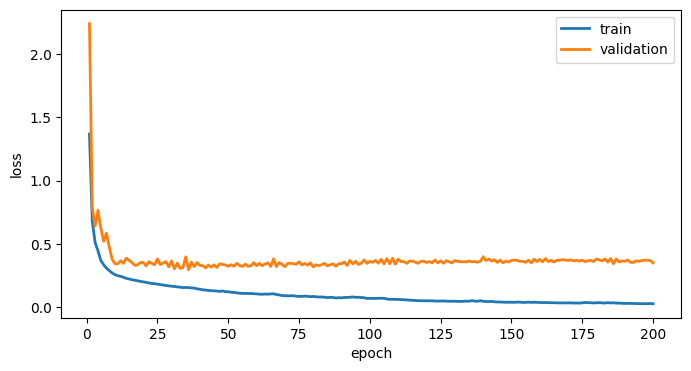

In [ ]:
train_curves = []
val_curves = []
models=[]
for k in range(len(folds)):
    train_mask, val_mask = spatial_masks(k)
    print(f"Fold {k + 1}/{len(folds)}")
    # Assuming fit() returns (train_curve, val_curve)
    model, train_curve, val_curve = fit(train_days, train_mask, val_mask)
    models.append(model)
    train_curves.append(train_curve)
    val_curves.append(val_curve)

# Compute mean curves across all folds
mean_train_curve = np.mean(train_curves, axis=0)
mean_val_curve = np.mean(val_curves, axis=0)

# Find the best epoch based on the mean validation loss
best_epoch = int(mean_val_curve.argmin()) + 1
print("best epoch:", best_epoch)

# Plotting
epochs = range(1, len(mean_train_curve) + 1)

plt.figure(figsize=(8, 4))
plt.plot(epochs, mean_train_curve, label="train", lw=2)
plt.plot(epochs, mean_val_curve, label="validation", lw=2)
# plt.axvline(best_epoch, ls="--", c="gray")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.legend()
plt.show()

In [ ]:
obs_tr = data["y"][train_days]
for k in range(len(folds)):
    train_mask, val_mask = spatial_masks(k)
    model, _ ,_= fit(train_days, train_mask, epochs=best_epoch)
    pred = predict(model, train_days)
    m = metrics(pred[:, val_mask], obs_tr[:, val_mask])          # held-out cells only
    print(f"Fold {k + 1}: " + "  ".join(f"{key}={v:.4f}" for key, v in m.items()))

Fold 1: mae=0.3032  rmse=0.4714  me=0.0441  ioa=0.9003  r=0.8177
Fold 2: mae=0.5105  rmse=1.2426  me=-0.1598  ioa=0.6523  r=0.6880
Fold 3: mae=0.4508  rmse=0.7417  me=0.0316  ioa=0.8953  r=0.8201
Fold 4: mae=0.6349  rmse=1.2483  me=-0.0339  ioa=0.7574  r=0.6421
Fold 5: mae=1.0395  rmse=1.5846  me=-0.2450  ioa=0.7750  r=0.6391


In [ ]:
all_cells = np.ones((h, w), dtype=bool)                          # no spatial masking now
model, _ ,_ = fit(train_days, all_cells, epochs=best_epoch)

obs = data["y"][test_days]
mean_pred = predict(model, test_days)                            # (5, 80, 100)

print("Test days 11-15 overall:",
      "  ".join(f"{k}={v:.4f}" for k, v in metrics(mean_pred, obs).items()))
for i in range(len(test_days)):
    print(f"  day {11 + i}:",
          "  ".join(f"{k}={v:.4f}" for k, v in metrics(mean_pred[i], obs[i]).items()))

np.save(f"{out_dir}/test_pred.npy", mean_pred)
np.save(f"{out_dir}/test_obs.npy", obs)

Test days 11-15 overall: mae=0.6117  rmse=1.2078  me=-0.3797  ioa=0.8824  r=0.8564
  day 11: mae=0.5553  rmse=1.0866  me=-0.4112  ioa=0.8642  r=0.8639
  day 12: mae=0.7180  rmse=1.4585  me=-0.5330  ioa=0.8610  r=0.8735
  day 13: mae=0.7328  rmse=1.3951  me=-0.4724  ioa=0.8736  r=0.8517
  day 14: mae=0.6079  rmse=1.1686  me=-0.2253  ioa=0.8903  r=0.8303
  day 15: mae=0.4447  rmse=0.8213  me=-0.2566  ioa=0.9321  r=0.9015


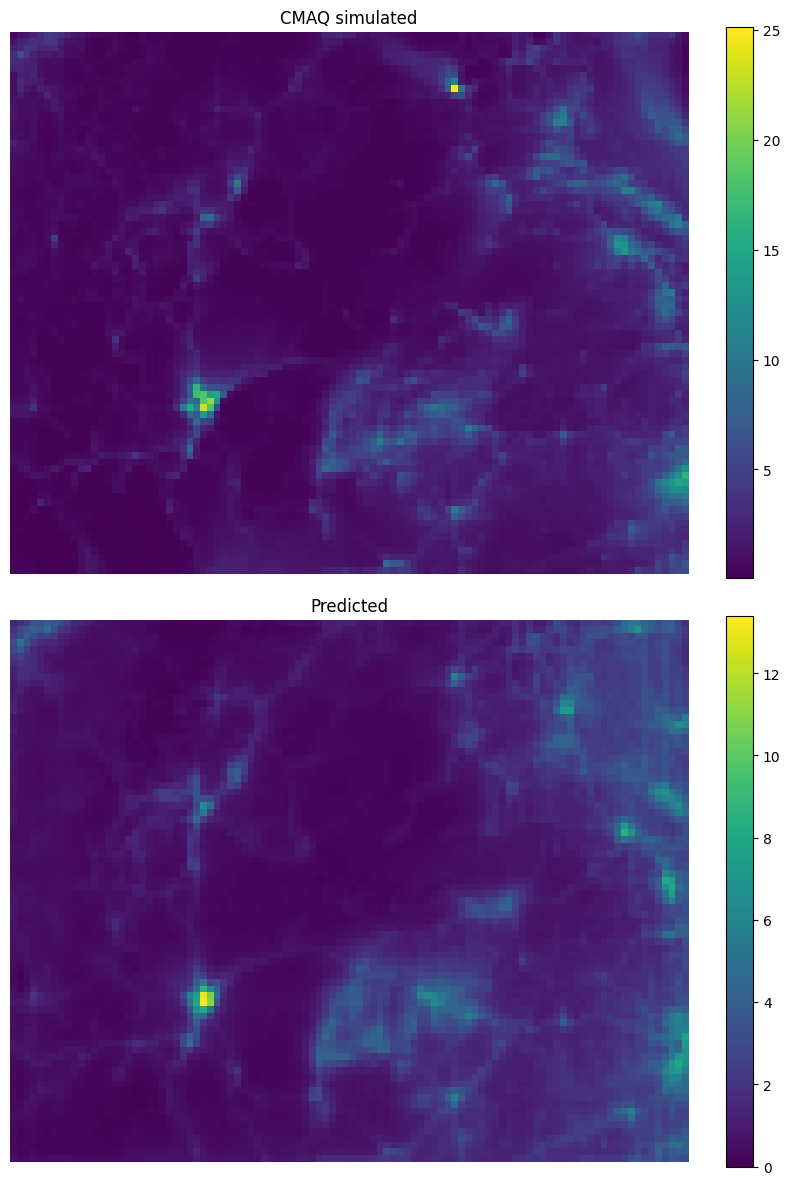

In [ ]:
d = 0  # 0 = day 11
fig, ax = plt.subplots(2, 1, figsize=(8, 12))

for a, im, t in zip(
    ax,
    [obs[d], mean_pred[d]],
    ["CMAQ simulated", "Predicted"],
):
  h_ = a.imshow(im, cmap="viridis")
  a.set_title(t)
  a.axis("off")
  plt.colorbar(h_, ax=a, fraction=0.046)

plt.tight_layout()
plt.show()

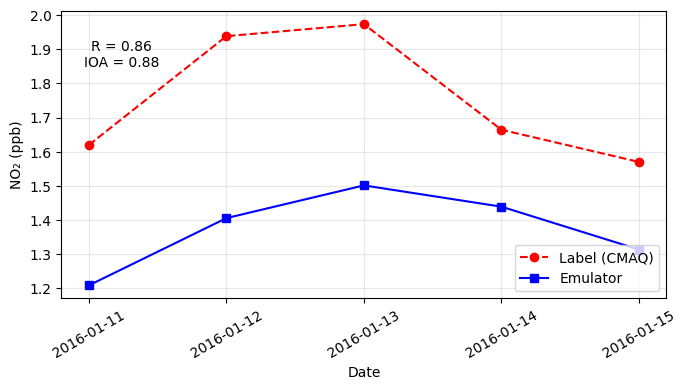

In [ ]:
dates = np.datetime_as_string(times[test_days], unit="D")
o_avg = obs.mean(axis=(1, 2))                          # domain average per day
p_avg = mean_pred.mean(axis=(1, 2))
# m = metrics(p_avg, o_avg)
m = metrics(mean_pred, obs)
plt.figure(figsize=(7, 4))
plt.plot(dates, o_avg, "--o", c="red", label="Label (CMAQ)")        # same style as the paper:
plt.plot(dates, p_avg, "-s", c="blue", label="Emulator")            # CMAQ red dashed, emulator blue
plt.text(0.1, 0.90, f"R = {m['r']:.2f}\nIOA = {m['ioa']:.2f}",
         transform=plt.gca().transAxes, ha="center", va="top")
plt.ylabel("NO₂ (ppb)"); plt.xlabel("Date")
plt.xticks(rotation=30); plt.grid(alpha=0.3); plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(f"{out_dir}/test_timeseries.png", dpi=200)
plt.show()

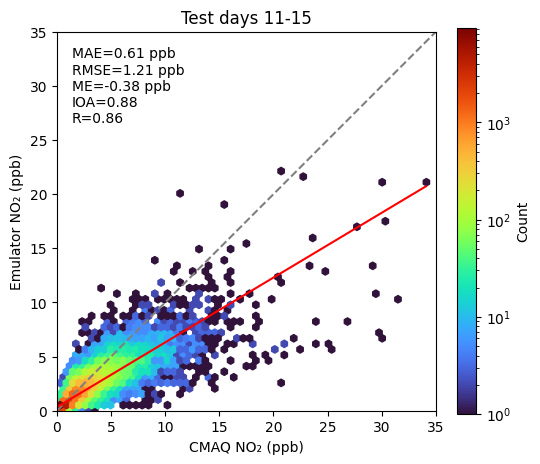

In [ ]:
from matplotlib.colors import LogNorm

o, p = obs.ravel(), mean_pred.ravel()                  # all pixels of the 5 test days
m = metrics(mean_pred, obs)
lim = np.ceil(max(o.max(), p.max()) / 5) * 5           # axis limit, rounded up to a multiple of 5

fig, ax = plt.subplots(figsize=(5.5, 5))
hb = ax.hexbin(o, p, gridsize=60, extent=(0, lim, 0, lim), mincnt=1, cmap="turbo", norm=LogNorm())
ax.plot([0, lim], [0, lim], "--", c="gray")            # dashed gray 1:1 line
slope, intercept = np.polyfit(o, p, 1)                 # red linear regression line
ax.plot([0, o.max()], [intercept, intercept + slope * o.max()], c="red")
ax.set_xlim(0, lim); ax.set_ylim(0, lim); ax.set_aspect("equal")
ax.set_xlabel("CMAQ NO₂ (ppb)"); ax.set_ylabel("Emulator NO₂ (ppb)")
ax.set_title("Test days 11-15")
ax.text(0.04, 0.96,
        f"MAE={m['mae']:.2f} ppb\nRMSE={m['rmse']:.2f} ppb\nME={m['me']:.2f} ppb\n"
        f"IOA={m['ioa']:.2f}\nR={m['r']:.2f}",
        transform=ax.transAxes, va="top")
plt.colorbar(hb, ax=ax, label="Count", fraction=0.046)
plt.tight_layout()
plt.savefig(f"{out_dir}/test_hexbin.png", dpi=200)
plt.show()

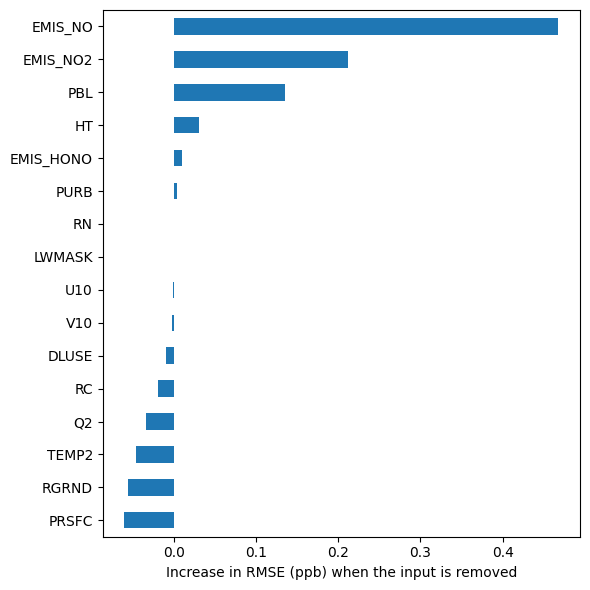

EMIS_NO      0.467670
EMIS_NO2     0.212544
PBL          0.135168
HT           0.030495
EMIS_HONO    0.010326
PURB         0.003598
RN           0.000098
LWMASK       0.000068
U10         -0.001190
V10         -0.002367
DLUSE       -0.009598
RC          -0.019579
Q2          -0.033884
TEMP2       -0.045915
RGRND       -0.056076
PRSFC       -0.059839
dtype: float64


In [ ]:
base_rmse = root_mean_squared_error(obs.ravel(), mean_pred.ravel())
names = data["channel_names"]

# group the DLUSE one-hot channels so they count as one variable
groups = {n: [i] for i, n in enumerate(names) if not n.startswith("DLUSE_")}
groups["DLUSE"] = [i for i, n in enumerate(names) if n.startswith("DLUSE_")]

importance = {}
for g, idx in groups.items():
    Xp = X[test_days].clone()
    Xp[:, idx] = X[train_days][:, idx].mean(dim=(0, 2, 3), keepdim=True)   # replace with training mean
    with torch.no_grad():
        z = model.eval()(Xp.to(device)).cpu().numpy()[:, 0]
    importance[g] = root_mean_squared_error(obs.ravel(), prep.inverse_y(z).ravel()) - base_rmse

imp = pd.Series(importance).sort_values()
imp.plot.barh(figsize=(6, 6), color="tab:blue")
plt.xlabel("Increase in RMSE (ppb) when the input is removed")
plt.tight_layout()
plt.savefig(f"{out_dir}/feature_importance.png", dpi=200)
plt.show()
print(imp.sort_values(ascending=False))